# Model 02 — Two-stage prediction of Commander trust: eye tracking (stage 1) + conversation (stage 2)

**Inputs:** `data/eye_features_by_block.csv` (`feature_extraction/01_eye_features.ipynb`) and `data/speech_features_by_block.csv` (`feature_extraction/02b_conversation_features.ipynb`).
**Target:** the Commander's post-block trust in the North UAV and in the South UAV (MDMT, 0–7).

**Design**
1. **Stage 1 — eye tracking → P(Low-Low).** Logistic regression on within-Commander-centered eye features separates
   Low-Low blocks from the other two (`models/01_reliability_eye_tracking.ipynb`: Low-Low is recognised almost perfectly).
2. **Stage 2 — P(Low-Low) + conversation about that UAV → trust in that UAV.** Linear regression on the stage-1
   probability plus a small set of conversation features **about the UAV being rated**: the mean sentiment of
   sentences mentioning it, and how often it is mentioned (per minute). For North trust these are the North
   features, for South trust the South features. What stage 1 cannot provide — the High-High vs Mixed difference
   (large for South trust) and differences between Commanders — is what conversation would have to add.

   A block in which a speaker never mentions the UAV gets sentiment 0 (no evaluation expressed; neutral on
   sentimentr's scale). This is a fixed rule, so it uses no information from other blocks.

| Model | Stage-2 inputs | Role |
|---|---|---|
| Mean | none | chance reference |
| Low-Low (oracle) | true Low-Low indicator | ceiling for stage 1 alone |
| Condition (oracle) | true condition (3 levels) | what knowing the condition exactly would give |
| Stage 1 only | P(Low-Low) | eye tracking alone, through stage 1 |
| Stage 1 + Commander speech | P(Low-Low) + Commander sentiment and mentions of that UAV (2) | proposed model |
| Stage 1 + Commander + IS speech | P(Low-Low) + the same for both operators (4) | adds the IS operator (trust contagion channel) |
| Speech only | the four conversation features, no eye tracking | what conversation does on its own |

**Validation.** Outer 5-fold cross-validation grouped by Commander, repeated 10 times; identical splits for all models.
Stage 1 is cross-fitted (cross-fitting): the stage-1 probabilities used to train stage 2 come from models that did not
see those Commanders. In-sample probabilities are over-confident, so within each outer training set stage 1 is
fitted on 4/5 of the training Commanders and predicts the remaining 1/5, five times; the test Commanders'
probabilities come from stage 1 fitted on all training Commanders. Stage-1 `C` is tuned inside the training folds. Stage 2 has at most five inputs, so it is
an ordinary (unpenalised) linear regression.

**Metrics.** Held-out R², mean absolute error, and **beyond-condition r**: correlation between how far a model's
prediction departs from the condition-oracle prediction and how far actual trust departs from it. It asks whether a
model predicts which Commanders trust more or less than their condition's average (0 = no).

In [1]:
import os
from pathlib import Path
# Run from anywhere inside the repository: paths below are relative to the repository root
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "feature_extraction").is_dir())
os.chdir(REPO)

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
warnings.filterwarnings("ignore", category=UserWarning)

EYE_PATH = "data/eye_features_by_block.csv"
SPEECH_PATH = "data/speech_features_by_block.csv"
FIG_DIR = "figures/02_trust_two_stage"
os.makedirs(FIG_DIR, exist_ok=True)

TARGETS = {"MDMT_North_C": "Trust in North UAV", "MDMT_South_C": "Trust in South UAV"}
N_REPEATS = 10
C_GRID = [0.01, 0.03, 0.1, 0.3, 1, 3]

## 1. Data

Blocks with eye-tracking and conversation data; Commanders with all three blocks. Eye features are centered within
Commander (as in the eye-tracking model). Conversation features are **not** centered, so they can carry differences between
Commanders.

In [2]:
EYE = ["North_dwell_frac", "South_dwell_frac", "North_fix_rate", "South_fix_rate",
       "North_fix_dur_mean", "South_fix_dur_mean", "pupil_mean", "pupil_sd", "blink_frac", "fix_rate", "fix_dur_mean",
       "sac_rate", "sac_amp_mean", "sac_peakvel_px_mean", "sac_dur_mean", "SGE", "GTE", "p_N_to_S", "p_S_to_N",
       "NS_switch_rate"]
UAV_OF = {"MDMT_North_C": "north", "MDMT_South_C": "south"}


def speech_features(uav, speakers):
    # conversation features about one UAV: sentiment of sentences mentioning it, and mentions per minute
    return [f"{uav}_{k}_{s}" for s in speakers for k in ("sentiment", "mentions_per_min")]

eye = pd.read_csv(EYE_PATH)
speech = pd.read_csv(SPEECH_PATH)
data = eye.merge(speech, on=["ID", "Reliability"], how="inner")
n_blocks = data.groupby("ID")["Reliability"].nunique()
data = data[data["ID"].isin(n_blocks[n_blocks == 3].index)].reset_index(drop=True)
data["condition"] = data["Reliability"].map({"HH": 0, "M": 1, "LL": 2})
data["is_LL"] = (data["condition"] == 2).astype(int)
for c in EYE:
    data[c + "_c"] = data[c] - data.groupby("ID")[c].transform("mean")
for c in [col for col in data if col.endswith(("_sentiment_C", "_sentiment_IS"))]:
    data[c] = data[c].fillna(0.0)                                  # UAV never mentioned -> neutral
EYE_C = [c + "_c" for c in EYE]
print(f"{len(data)} blocks from {data['ID'].nunique()} Commanders")
data.groupby("Reliability")[list(TARGETS)].mean().loc[["HH", "M", "LL"]].round(2)

117 blocks from 39 Commanders


,MDMT_North_C,MDMT_South_C
Reliability,,
HH,5.35,5.66
M,5.64,3.67
LL,2.81,2.61


## 2. Two-stage cross-validation

In [3]:
def stage1(X_tr, y_tr, g_tr, X_te, seed):
    # P(Low-Low): tuned on training Commanders; training probabilities cross-fitted
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    make = lambda C=1.0: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    C = GridSearchCV(make(), {"logisticregression__C": C_GRID}, cv=cv, scoring="roc_auc").fit(
        X_tr, y_tr, groups=g_tr).best_params_["logisticregression__C"]
    p_tr = cross_val_predict(make(C), X_tr, y_tr, groups=g_tr, cv=cv, method="predict_proba")[:, 1]
    p_te = make(C).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    return p_tr[:, None], p_te[:, None]


MODELS = ["Mean", "Low-Low (oracle)", "Condition (oracle)", "Stage 1 only",
          "Stage 1 + Commander speech", "Stage 1 + Commander + IS speech", "Speech only"]


def run_cv(df, target, n_repeats=N_REPEATS):
    y, g = df[target].to_numpy(), df["ID"].to_numpy()
    X_eye, ll = df[EYE_C].to_numpy(), df["is_LL"].to_numpy()
    D3 = np.column_stack([df["condition"] == 1, df["condition"] == 2]).astype(float)
    uav = UAV_OF[target]
    S_c, S_all = df[speech_features(uav, ["C"])].to_numpy(), df[speech_features(uav, ["C", "IS"])].to_numpy()
    preds = {m: np.zeros((n_repeats, len(y))) for m in MODELS}
    rows = []
    for rep in range(n_repeats):
        for tr, te in GroupKFold(n_splits=5, shuffle=True, random_state=rep).split(X_eye, y, g):
            seed = 100 + rep
            P_tr, P_te = stage1(X_eye[tr], ll[tr], g[tr], X_eye[te], seed)
            fit = lambda Z_tr, Z_te: LinearRegression().fit(Z_tr, y[tr]).predict(Z_te)
            p = {"Mean": np.full(len(te), y[tr].mean()),
                 "Low-Low (oracle)": LinearRegression().fit(ll[tr, None], y[tr]).predict(ll[te, None]),
                 "Condition (oracle)": LinearRegression().fit(D3[tr], y[tr]).predict(D3[te]),
                 "Stage 1 only": LinearRegression().fit(P_tr, y[tr]).predict(P_te),
                 "Stage 1 + Commander speech": fit(np.hstack([P_tr, S_c[tr]]), np.hstack([P_te, S_c[te]])),
                 "Stage 1 + Commander + IS speech": fit(np.hstack([P_tr, S_all[tr]]), np.hstack([P_te, S_all[te]])),
                 "Speech only": fit(S_all[tr], S_all[te])}
            for m, v in p.items():
                preds[m][rep, te] = v
        oracle = preds["Condition (oracle)"][rep]
        for m in MODELS:
            pr = preds[m][rep]
            beyond = (np.corrcoef(pr - oracle, y - oracle)[0, 1]
                      if m not in ("Mean", "Condition (oracle)", "Low-Low (oracle)") else np.nan)
            rows.append({"repeat": rep, "model": m, "R2": r2_score(y, pr), "MAE": mean_absolute_error(y, pr),
                         "beyond_condition_r": beyond})
    return {"scores": pd.DataFrame(rows), "preds": preds, "y": y, "cond": df["condition"].to_numpy()}


results = {t: run_cv(data, t) for t in TARGETS}

## 3. Results (held-out Commanders, mean ± SD over repeats)

In [4]:
def summary_table(res):
    s = res["scores"].groupby("model")[["R2", "MAE", "beyond_condition_r"]].agg(["mean", "std"])
    return s.loc[MODELS].round(3)

pd.concat({TARGETS[t]: summary_table(r) for t, r in results.items()}, names=["target"])

R2           MAE        beyond_condition_r       
                                                     mean    std   mean    std               mean    std
target             model                                                                                
Trust in North UAV Mean                            -0.012  0.008  1.436  0.006                NaN    NaN
                   Low-Low (oracle)                 0.534  0.007  0.903  0.008                NaN    NaN
                   Condition (oracle)               0.533  0.007  0.906  0.006                NaN    NaN
                   Stage 1 only                     0.463  0.008  0.997  0.008             -0.013  0.033
                   Stage 1 + Commander speech       0.429  0.024  1.021  0.013             -0.071  0.039
                   Stage 1 + Commander + IS speech  0.417  0.026  1.027  0.016             -0.057  0.037
                   Speech only                     -0.089  0.055  1.474  0.034             -0.013  0.022
Trust in South UAV Mean                            -0.015  0.010  1.478  0.007                NaN    NaN
                   Low-Low (oracle)                 0.290  0.009  1.211  0.007                NaN    NaN
                   Condition (oracle)               0.504  0.009  0.970  0.010                NaN    NaN
                   Stage 1 only                     0.235  0.011  1.263  0.009              0.016  0.012
                   Stage 1 + Commander speech       0.299  0.019  1.223  0.015              0.160  0.019
                   Stage 1 + Commander + IS speech  0.349  0.021  1.161  0.019              0.229  0.024
                   Speech only                      0.210  0.015  1.266  0.013              0.246  0.013

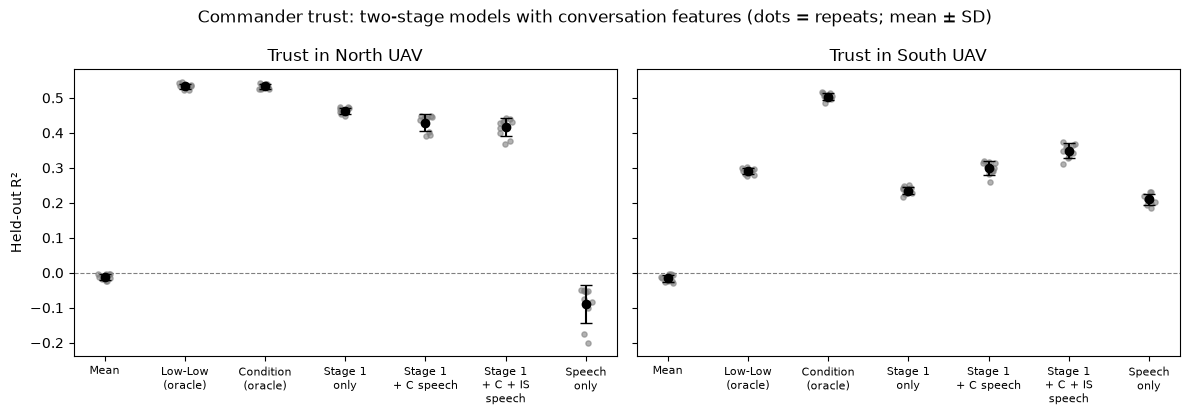

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (t, res) in zip(axes, results.items()):
    s = res["scores"]
    for i, m in enumerate(MODELS):
        v = s.loc[s["model"] == m, "R2"]
        ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.08, 0.08, len(v)), v,
                   s=14, color="grey", alpha=0.6)
        ax.errorbar(i, v.mean(), yerr=v.std(), fmt="o", color="black", capsize=4)
    ax.axhline(0, ls="--", color="grey", lw=0.8)
    ax.set_xticks(range(len(MODELS)))
    short = {"Low-Low (oracle)": "Low-Low\n(oracle)", "Condition (oracle)": "Condition\n(oracle)",
             "Stage 1 only": "Stage 1\nonly", "Stage 1 + Commander speech": "Stage 1\n+ C speech",
             "Stage 1 + Commander + IS speech": "Stage 1\n+ C + IS\nspeech", "Speech only": "Speech\nonly"}
    ax.set_xticklabels([short.get(m, m) for m in MODELS], fontsize=8)
    ax.set_title(TARGETS[t])
axes[0].set_ylabel("Held-out R²")
fig.suptitle("Commander trust: two-stage models with conversation features (dots = repeats; mean ± SD)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/trust_model_comparison.png", dpi=200); plt.show()

## 4. Stage-2 coefficients

The full model (stage 1 + Commander + IS speech) refitted on all Commanders, with the stage-1 probability
cross-fitted. Coefficients are per 1 SD of each input, so they are comparable in size. These describe the fitted
model; held-out performance (Section 3) is what says whether the conversation features help.

In [6]:
def full_model_coefficients(df, target, seed=0):
    X_eye, ll, g = df[EYE_C].to_numpy(), df["is_LL"].to_numpy(), df["ID"].to_numpy()
    P, _ = stage1(X_eye, ll, g, X_eye[:1], seed)
    feats = speech_features(UAV_OF[target], ["C", "IS"])
    Z = StandardScaler().fit_transform(np.hstack([P, df[feats].to_numpy()]))
    m = LinearRegression().fit(Z, df[target])
    return pd.Series(m.coef_, index=["P(Low-Low)"] + [f.replace(UAV_OF[target] + "_", "") for f in feats])

coef_tab = pd.DataFrame({TARGETS[t]: full_model_coefficients(data, t) for t in TARGETS})
coef_tab.round(3)

,Trust in North UAV,Trust in South UAV
P(Low-Low),-1.200,-0.697
sentiment_C,0.061,0.356
mentions_per_min_C,0.070,-0.213
sentiment_IS,-0.129,0.440
mentions_per_min_IS,-0.060,-0.105


## 5. Permutation test: is the conversation gain larger than chance?

Repeated splits reuse the same Commanders, so their spread understates uncertainty. Here the conversation features
are shuffled across blocks and the whole stage-2 evaluation is repeated (stage-1 probabilities do not depend on the
conversation features, so they are computed once per fold and reused). Statistic: held-out R² of
*stage 1 + Commander + IS speech* minus *stage 1 only*, averaged over the 10 repeats.

- **Shuffle all:** conversation features reassigned to random blocks — does conversation add anything?
- **Shuffle within condition:** reassigned only among blocks of the same condition, so the link between conversation
  and condition is kept — does conversation add anything **beyond the condition**?

p = (1 + number of shuffles with a gain ≥ the observed gain) / (1 + number of shuffles).

In [7]:
N_PERM = 500
X_eye, ll_all, g_all = data[EYE_C].to_numpy(), data["is_LL"].to_numpy(), data["ID"].to_numpy()
CACHE = []                                                          # (repeat, train, test, P_train, P_test)
for rep in range(N_REPEATS):
    for tr, te in GroupKFold(n_splits=5, shuffle=True, random_state=rep).split(X_eye, ll_all, g_all):
        P_tr, P_te = stage1(X_eye[tr], ll_all[tr], g_all[tr], X_eye[te], 100 + rep)
        CACHE.append((rep, tr, te, P_tr, P_te))


def stage2_r2(target, S):
    # mean held-out R2 over repeats for stage 1 (+ S); S = blocks x features array, or None
    y = data[target].to_numpy()
    out = []
    for rep in range(N_REPEATS):
        pred = np.zeros(len(y))
        for rp, tr, te, P_tr, P_te in CACHE:
            if rp == rep:
                Z_tr = P_tr if S is None else np.hstack([P_tr, S[tr]])
                Z_te = P_te if S is None else np.hstack([P_te, S[te]])
                pred[te] = make_pipeline(SimpleImputer(strategy="median"), LinearRegression()).fit(Z_tr, y[tr]).predict(Z_te)
        out.append(r2_score(y, pred))
    return float(np.mean(out))


rng = np.random.default_rng(0)
cond = data["condition"].to_numpy()
perm_rows = []
for t in TARGETS:
    S = data[speech_features(UAV_OF[t], ["C", "IS"])].to_numpy()
    base = stage2_r2(t, None)
    observed = stage2_r2(t, S) - base
    null_all, null_within = [], []
    for _ in range(N_PERM):
        null_all.append(stage2_r2(t, S[rng.permutation(len(S))]) - base)
        idx = np.arange(len(S))
        for k in range(3):
            w = np.flatnonzero(cond == k)
            idx[w] = rng.permutation(w)
        null_within.append(stage2_r2(t, S[idx]) - base)
    null_all, null_within = np.array(null_all), np.array(null_within)
    perm_rows.append({"target": TARGETS[t], "R2 gain from conversation": observed,
                      "p (shuffle all)": (1 + (null_all >= observed).sum()) / (1 + N_PERM),
                      "p (shuffle within condition)": (1 + (null_within >= observed).sum()) / (1 + N_PERM),
                      "95th percentile of gain under shuffle within condition": np.quantile(null_within, 0.95)})
pd.DataFrame(perm_rows).set_index("target").round(4)

,R2 gain from conversation,p (shuffle all),p (shuffle within condition),95th percentile of gain under shuffle within condition
target,,,,
Trust in North UAV,-0.0465,0.8703,0.8842,-0.0015
Trust in South UAV,0.1140,0.0020,0.0020,0.0402


## 6. Exploratory: do other conversation features add to the main model?

Each row adds one feature family to the main stage-2 model (stage 1 + per-UAV sentiment and mentions, Commander and
IS), or swaps sentimentr for AFINN. Same folds and stage-1 probabilities as Section 5. These comparisons were run
after the main model was chosen; they are reported for completeness, not as confirmatory tests.

In [8]:
def families(uav):
    main = speech_features(uav, ["C", "IS"])
    both = lambda names: [f"{n}_{s}" for n in names for s in ("C", "IS")]
    return {
        "Stage 1 only": None,
        "Main model": main,
        "Main + per-UAV AFINN": main + both([f"{uav}_afinn"]),
        "Main with AFINN instead of sentimentr": both([f"{uav}_afinn"]) + both([f"{uav}_mentions_per_min"]),
        "Main + per-UAV NRC arousal and dominance": main + both([f"{uav}_nrc_A", f"{uav}_nrc_D"]),
        "Main + amount (words/min, words/utterance)": main + both(["words_per_min", "words_per_utt"]),
        "Main + general sentiment (mean, negative share)": main + both(["sentiment_mean", "neg_share"]),
        "Main + timing (speaking share, switches, latency)": main + ["speaking_share_C", "switches_per_min",
                                                                       "response_latency_C"],
    }

for c in [c for c in data if "_afinn_" in c]:
    data[c] = data[c].fillna(0.0)                                  # UAV never mentioned -> neutral
explore = {}
for t in TARGETS:
    explore[TARGETS[t]] = {name: stage2_r2(t, None if cols is None else data[cols].to_numpy())
                           for name, cols in families(UAV_OF[t]).items()}
pd.DataFrame(explore).round(3).rename_axis("stage-2 inputs (held-out R²)")

,Trust in North UAV,Trust in South UAV
stage-2 inputs (held-out R²),,
Stage 1 only,0.463,0.235
Main model,0.417,0.349
Main + per-UAV AFINN,0.417,0.322
Main with AFINN instead of sentimentr,0.416,0.283
Main + per-UAV NRC arousal and dominance,0.376,0.344
"Main + amount (words/min, words/utterance)",0.334,0.268
"Main + general sentiment (mean, negative share)",0.355,0.307
"Main + timing (speaking share, switches, latency)",0.374,0.320


## Notes and limitations

- **Scenario confound.** Each condition used one fixed scenario video, so both eye tracking and conversation partly
  describe the scenario. Beyond-condition r is the test of whether conversation tracks trust itself.
- **Sentiment is not validated against human ratings.** sentimentr handles *correct/incorrect* and negation, but
  scores "false positive" near neutral and descriptive error talk ("it's not seeing those cars") as 0 (`feature_extraction/02b_conversation_features.ipynb`).
- **Most blocks have few UAV-specific sentences.** Blocks without a mention get sentiment 0, which may dilute effects.
- **UAV mentions** use a keyword rule (north/left, south/right) that has not been validated against hand coding.
- **Concurrent speech.** Conversation during a block happens before the trust rating, but it is not independent of the
  rating: operators may talk about the UAVs because they already distrust them. This is prediction, not mechanism.
- **Sample.** Commanders with both eye tracking and usable conversation data; differences of a few hundredths in R²
  are within split-to-split variation.